# Nomor 3 · Visualisasi fundamental Apple

**Tujuan:** membaca kinerja pendapatan, profitabilitas, dan kas untuk membedakan
informasi deskriptif dari informasi strategis dalam skenario perencanaan bisnis.

Tautan tugas bernama [Apple Stocks](https://www.kaggle.com/datasets/blixture/apple-stocks),
tetapi file lokal memuat **SEC Financial Facts and Filings**, bukan harga saham OHLCV.
Metadata menyatakan `price_data_included: false`. Karena itu notebook tidak membuat return saham,
volatilitas pasar, RSI, candlestick, atau rekomendasi beli/jual.

Analisis utama memakai **tahun fiskal penuh 2019–2025** yang tercakup dalam snapshot lokal.
Observasi 2026 mencakup periode parsial dan tidak dicampur dengan satu tahun penuh.
Jalankan **Restart Kernel and Run All**. Tidak ada permintaan jaringan saat eksekusi.

## 1. Pertanyaan dan arti strategis

1. Bagaimana pendapatan dan laba bersih berubah dari tahun ke tahun?
2. Apakah perubahan laba disertai perubahan margin operasi dan margin bersih?
3. Apakah kenaikan laba sejalan dengan arus kas operasi serta kas setelah belanja modal?
4. Apa implikasinya untuk kehati-hatian perencanaan kapasitas investasi pada skenario bisnis?

**Informasi** menjelaskan perubahan metrik. **Informasi strategis** menghubungkan perubahan
tersebut dengan kebutuhan mengevaluasi anggaran, risiko, dan konsistensi pembentukan kas.
Usulan tindakan tetap memerlukan data rencana dan penjelasan laporan lengkap.

In [1]:
from pathlib import Path
import hashlib
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

def temukan_root():
    # Mendukung peluncuran dari folder Analisis, RISET30OKTOBER, atau workspace.
    for calon in [Path.cwd(), *Path.cwd().parents]:
        for lokasi in [calon, calon / 'RISET30OKTOBER']:
            if (lokasi / 'Battery/Dataset/ev_battery_health.csv').exists() and (lokasi / 'Apple/Dataset/financial_facts.csv').exists():
                return lokasi
    raise FileNotFoundError('Letakkan folder Analisis di dalam RISET30OKTOBER, bersama Battery dan Apple.')

ROOT = temukan_root()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'savefig.dpi': 160})
WARNA = {'utama':'#156B86', 'hijau':'#087D59', 'ungu':'#7045D9', 'jingga':'#B75B30', 'abu':'#64706F'}

def angka(v, desimal=2):
    return f'{v:,.{desimal}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def simpan_grafik(fig, nama):
    fig.savefig(HASIL / nama, bbox_inches='tight')
    plt.show()

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [2]:
SUMBER = ROOT / 'Apple/Dataset'
HASIL = ROOT / 'Analisis/hasil/apple'
HASIL.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(SUMBER / 'financial_facts.csv')
filings = pd.read_csv(SUMBER / 'filings.csv')
metadata = json.loads((SUMBER / 'refresh_metadata.json').read_text())
profile = json.loads((SUMBER / 'company_profile.json').read_text())
dictionary = pd.read_csv(SUMBER / 'data_dictionary.csv')
assert metadata['price_data_included'] is False
assert len(raw) == metadata['financial_fact_rows']
assert len(filings) == metadata['filing_rows']
print('Perusahaan:', profile['entityName'], '| Ticker:', profile['ticker'])
print('Snapshot diunduh pembuat dataset:', metadata['refreshed_at_utc'])
print('Financial facts:', raw.shape, '| Filing:', filings.shape)
display(dictionary)
display(raw[['concept','unit','value','start','end','fy','form','filed','accn']].head())

Perusahaan: Apple Inc. | Ticker: AAPL
Snapshot diunduh pembuat dataset: 2026-10-19T23:10:10.189791+00:00
Financial facts: (25135, 14) | Filing: (1002, 11)


,field,description
0,taxonomy,"XBRL taxonomy, such as us-gaap or dei"
1,concept,XBRL concept/tag name
2,label,SEC human-readable concept label
3,description,SEC concept description
4,unit,"Measurement unit, such as USD, shares, or USD/..."
5,value,Reported numeric value
6,accn,SEC accession number for audit traceability
7,form,SEC filing form
8,filed,Date the fact was filed
9,fy,Fiscal year reported by the filing


,concept,unit,value,start,end,fy,form,filed,accn
0,EntityCommonStockSharesOutstanding,shares,"895,816,758.00",NaN,2009-06-27,"2,009.00",10-Q,2009-07-22,0001193125-09-153165
1,EntityPublicFloat,USD,"94,593,000,000.00",NaN,2009-03-28,"2,009.00",10-Q,2009-07-22,0001193125-09-153165
2,AccountsPayable,USD,"5,520,000,000.00",NaN,2008-09-27,"2,009.00",10-Q,2009-07-22,0001193125-09-153165
3,AccountsPayable,USD,"4,854,000,000.00",NaN,2009-06-27,"2,009.00",10-Q,2009-07-22,0001193125-09-153165
4,AccountsReceivableNetCurrent,USD,"2,422,000,000.00",NaN,2008-09-27,"2,009.00",10-Q,2009-07-22,0001193125-09-153165


## 2. Audit dan tantangan data XBRL

Satu baris adalah satu fakta keuangan untuk konsep, satuan, periode, dan filing tertentu.
Periode historis yang sama dapat muncul lagi sebagai angka pembanding pada filing berikutnya.
Fakta USD, jumlah saham, dan USD per saham tidak boleh dijumlahkan bersama.

- `start` kosong dapat menandai fakta **instant**, misalnya saldo aset pada tanggal tertentu.
- `frame` kosong bukan otomatis angka tidak valid. Label kalender SEC tidak menggantikan periode fiskal.
- `fy` menjelaskan tahun fokus filing, sehingga angka pembanding 2023 dapat muncul pada filing FY2025.
- Analisis memilih rentang `start`–`end` yang sesuai dan satuan USD. Tidak memakai `groupby(fy).sum()`.

In [3]:
audit = pd.DataFrame({'kosong':raw.isna().sum(), 'tipe':raw.dtypes.astype(str)})
display(audit)
print('Duplikasi baris persis:', raw.duplicated().sum())
assert raw['value'].notna().all()
facts = raw.copy()
for kolom in ['start','end','filed']:
    facts[kolom] = pd.to_datetime(facts[kolom], errors='coerce')
    assert facts[kolom].isna().sum() == raw[kolom].isna().sum()
facts['durasi_hari'] = (facts['end'] - facts['start']).dt.days + 1
assert facts[['end','filed']].notna().all().all()
assert not facts['filed'].lt(facts['end']).any()
print('Rentang akhir periode:', facts['end'].min().date(), 's.d.', facts['end'].max().date())
print('Form tersedia:', facts['form'].value_counts().to_dict())
display(facts.groupby('unit',dropna=False).size().rename('jumlah_fakta'))
audit.to_csv(HASIL / 'audit_missing.csv')

,kosong,tipe
taxonomy,0,str
concept,0,str
label,6,str
description,6,str
unit,0,str
value,0,float64
accn,0,str
form,0,str
filed,0,str
fy,569,float64


Duplikasi baris persis: 0
Rentang akhir periode: 2006-09-30 s.d. 2026-07-17
Form tersedia: {'10-Q': 15304, '10-K': 8503, '8-K': 1118, '10-K/A': 210}


unit
Store             6
USD           21919
USD/shares     1360
Year             13
pure            196
shares         1641
Name: jumlah_fakta, dtype: int64

## 3. Seleksi periode tahunan dengan jejak audit

Pilih 7 konsep `us-gaap`, satuan USD, form 10-K atau 10-K/A, periode 350–380 hari,
dan akhir periode dalam 2019–2025. Rentang ini mengakomodasi tahun fiskal 52 atau 53 minggu.

Untuk setiap periode, pilih **filing terbaru dalam snapshot yang memuat seluruh tujuh metrik**.
Seluruh metrik satu tahun harus berasal dari `accn`, `start`, dan `end` yang sama.
Ini mencegah pencampuran versi laporan dan penghitungan ganda angka pembanding.
Jika satu metrik hilang atau nilainya ambigu, notebook berhenti, bukan mengisi nol.

Nama tahun fiskal diambil dari tahun akhir periode Apple pada data terpilih. `fy` asli tetap
disimpan untuk audit dan tidak ditafsirkan sebagai tahun setiap nilai pembanding.
Pilihan filing terbaru ini bersifat retrospektif sesuai snapshot, bukan data point-in-time untuk backtest.

In [4]:
METRIK = {
    'RevenueFromContractWithCustomerExcludingAssessedTax':'pendapatan',
    'NetIncomeLoss':'laba_bersih',
    'GrossProfit':'laba_kotor',
    'OperatingIncomeLoss':'laba_operasi',
    'NetCashProvidedByUsedInOperatingActivities':'arus_kas_operasi',
    'PaymentsToAcquirePropertyPlantAndEquipment':'capex',
    'ResearchAndDevelopmentExpense':'riset_pengembangan',
}
calon = facts[
    facts['taxonomy'].eq('us-gaap') & facts['unit'].eq('USD')
    & facts['concept'].isin(METRIK) & facts['form'].isin(['10-K','10-K/A'])
    & facts['durasi_hari'].between(350,380) & facts['end'].dt.year.between(2019,2025)
].copy()
periode = ['start','end']
kunci = ['start','end','accn']
ambigu = calon.groupby(kunci+['concept'])['value'].nunique()
assert ambigu.le(1).all(), 'Nilai bertentangan dalam periode/filing/konsep yang sama.'
coverage = calon.groupby(kunci).agg(n_konsep=('concept','nunique'), filed=('filed','max')).reset_index()
lengkap = coverage[coverage['n_konsep'].eq(len(METRIK))]
terpilih = lengkap.sort_values(['end','filed','accn']).drop_duplicates(periode,keep='last')
assert len(terpilih) == 7, 'Periode tahunan lengkap 2019–2025 tidak ditemukan.'
jejak = calon.merge(terpilih[kunci], on=kunci, how='inner').drop_duplicates(kunci+['concept'])
assert len(jejak) == 7*len(METRIK)
assert set(jejak['unit']) == {'USD'}
annual = jejak.pivot(index=['start','end','accn'],columns='concept',values='value').rename(columns=METRIK).reset_index()
annual['tahun_fiskal'] = annual['end'].dt.year
annual = annual.sort_values('tahun_fiskal').reset_index(drop=True)
assert annual['tahun_fiskal'].tolist() == list(range(2019,2026))
assert annual[list(METRIK.values())].notna().all().all()
assert annual['pendapatan'].gt(0).all()
print(f'Baris calon terkait: {len(calon)}. Fakta terpilih: {len(jejak)}. Tahun analisis: {len(annual)}.')
display(jejak[['start','end','fy','concept','value','filed','form','accn']].tail(14))
display(annual[['tahun_fiskal','start','end','pendapatan','laba_bersih']])

Baris calon terkait: 126. Fakta terpilih: 49. Tahun analisis: 7.


,start,end,fy,concept,value,filed,form,accn
35,2023-10-01,2024-09-28,"2,025.00",NetIncomeLoss,"93,736,000,000.00",2025-10-31,10-K,0000320193-25-000079
36,2024-09-29,2025-09-27,"2,025.00",NetIncomeLoss,"112,010,000,000.00",2025-10-31,10-K,0000320193-25-000079
37,2022-09-25,2023-09-30,"2,025.00",OperatingIncomeLoss,"114,301,000,000.00",2025-10-31,10-K,0000320193-25-000079
38,2023-10-01,2024-09-28,"2,025.00",OperatingIncomeLoss,"123,216,000,000.00",2025-10-31,10-K,0000320193-25-000079
39,2024-09-29,2025-09-27,"2,025.00",OperatingIncomeLoss,"133,050,000,000.00",2025-10-31,10-K,0000320193-25-000079
40,2022-09-25,2023-09-30,"2,025.00",PaymentsToAcquirePropertyPlantAndEquipment,"10,959,000,000.00",2025-10-31,10-K,0000320193-25-000079
41,2023-10-01,2024-09-28,"2,025.00",PaymentsToAcquirePropertyPlantAndEquipment,"9,447,000,000.00",2025-10-31,10-K,0000320193-25-000079
42,2024-09-29,2025-09-27,"2,025.00",PaymentsToAcquirePropertyPlantAndEquipment,"12,715,000,000.00",2025-10-31,10-K,0000320193-25-000079
43,2022-09-25,2023-09-30,"2,025.00",ResearchAndDevelopmentExpense,"29,915,000,000.00",2025-10-31,10-K,0000320193-25-000079
44,2023-10-01,2024-09-28,"2,025.00",ResearchAndDevelopmentExpense,"31,370,000,000.00",2025-10-31,10-K,0000320193-25-000079


concept,tahun_fiskal,start,end,pendapatan,laba_bersih
0,2019,2018-09-30,2019-09-28,"260,174,000,000.00","55,256,000,000.00"
1,2020,2019-09-29,2020-09-26,"274,515,000,000.00","57,411,000,000.00"
2,2021,2020-09-27,2021-09-25,"365,817,000,000.00","94,680,000,000.00"
3,2022,2021-09-26,2022-09-24,"394,328,000,000.00","99,803,000,000.00"
4,2023,2022-09-25,2023-09-30,"383,285,000,000.00","96,995,000,000.00"
5,2024,2023-10-01,2024-09-28,"391,035,000,000.00","93,736,000,000.00"
6,2025,2024-09-29,2025-09-27,"416,161,000,000.00","112,010,000,000.00"


## 4. Perhitungan metrik

- Pertumbuhan tahunan = (nilai tahun sekarang / nilai tahun sebelumnya − 1) × 100%.
- Margin kotor/operasi/bersih = masing-masing jenis laba / pendapatan × 100%.
- **FCF sederhana** = arus kas operasi − pembayaran akuisisi aset tetap (capex).
  Ini definisi analitis yang dipakai konsisten di sini, bukan kas bebas yang pasti tersedia untuk dibelanjakan.
- Konversi satuan: seluruh nilai USD dibagi **1 miliar (10⁹)** hanya untuk tampilan grafik.
  File input menyimpan USD, bukan jutaan USD seperti tampilan laporan 10-K.

In [5]:
for label in ['pendapatan','laba_bersih','arus_kas_operasi','capex']:
    annual[label+'_yoy_pct'] = annual[label].pct_change()*100
for jenis in ['kotor','operasi','bersih']:
    annual['margin_'+jenis+'_pct'] = annual['laba_'+jenis]/annual['pendapatan']*100
annual['fcf_sederhana'] = annual['arus_kas_operasi']-annual['capex']
annual['fcf_yoy_pct'] = annual['fcf_sederhana'].pct_change()*100
annual['margin_fcf_pct'] = annual['fcf_sederhana']/annual['pendapatan']*100
display(annual[['tahun_fiskal','pendapatan_yoy_pct','laba_bersih_yoy_pct',
                'margin_operasi_pct','margin_bersih_pct','arus_kas_operasi','capex','fcf_sederhana']])
terkini, sebelumnya = annual.iloc[-1], annual.iloc[-2]

concept,tahun_fiskal,pendapatan_yoy_pct,laba_bersih_yoy_pct,margin_operasi_pct,margin_bersih_pct,arus_kas_operasi,capex,fcf_sederhana
0,2019,NaN,NaN,24.57,21.24,"69,391,000,000.00","10,495,000,000.00","58,896,000,000.00"
1,2020,5.51,3.90,24.15,20.91,"80,674,000,000.00","7,309,000,000.00","73,365,000,000.00"
2,2021,33.26,64.92,29.78,25.88,"104,038,000,000.00","11,085,000,000.00","92,953,000,000.00"
3,2022,7.79,5.41,30.29,25.31,"122,151,000,000.00","10,708,000,000.00","111,443,000,000.00"
4,2023,-2.80,-2.81,29.82,25.31,"110,543,000,000.00","10,959,000,000.00","99,584,000,000.00"
5,2024,2.02,-3.36,31.51,23.97,"118,254,000,000.00","9,447,000,000.00","108,807,000,000.00"
6,2025,6.43,19.50,31.97,26.92,"111,482,000,000.00","12,715,000,000.00","98,767,000,000.00"


## 5. Visual 1 Pendapatan dan laba dalam nominal

Dua panel garis dengan sumbu tahun yang sama menampilkan metrik dengan skala berbeda
tanpa menumpuk dua sumbu vertikal. Nilai sumbu mulai nol untuk menjaga konteks besaran.
Garis menyatakan urutan waktu, bukan ramalan di antara atau setelah tahun yang tersedia.

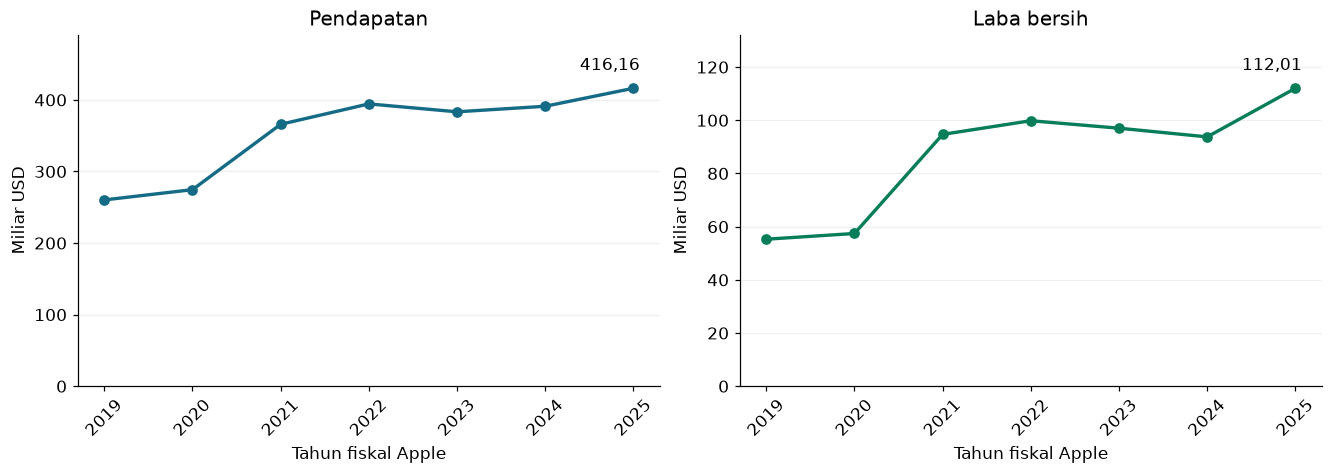

**Informasi:** FY2025 pendapatan **416,16 miliar USD** (6,43% YoY), sedangkan laba bersih **112,01 miliar USD** (19,50% YoY).

In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4.2), layout='constrained')
for ax, kol, judul, warna in zip(axes, ['pendapatan','laba_bersih'], ['Pendapatan','Laba bersih'],
                               [WARNA['utama'],WARNA['hijau']]):
    ax.plot(annual['tahun_fiskal'], annual[kol]/1e9, marker='o', linewidth=2.2,color=warna)
    ax.set(title=judul, xlabel='Tahun fiskal Apple',ylabel='Miliar USD',ylim=(0,annual[kol].max()/1e9*1.18))
    ax.set_xticks(annual['tahun_fiskal'])
    ax.tick_params(axis='x',labelrotation=45)
    ax.grid(axis='y',alpha=.2)
    ax.annotate(angka(terkini[kol]/1e9), (2025,terkini[kol]/1e9), xytext=(-35,12), textcoords='offset points')
simpan_grafik(fig,'01_pendapatan_laba.png')
display(Markdown(f'**Informasi:** FY2025 pendapatan **{angka(terkini["pendapatan"]/1e9)} miliar USD** '
                 f'({angka(terkini["pendapatan_yoy_pct"])}% YoY), sedangkan laba bersih '
                 f'**{angka(terkini["laba_bersih"]/1e9)} miliar USD** '
                 f'({angka(terkini["laba_bersih_yoy_pct"])}% YoY).'))

**Informasi strategis:** pertumbuhan penjualan dan laba menjadi titik awal evaluasi rencana bisnis,
tetapi laba bersih juga dipengaruhi pos di luar operasi. Untuk menilai keberlanjutan, bandingkan margin operasi
dan kas pada visual berikutnya. Angka ini tidak menentukan return saham.

## 6. Visual 2 Margin kotor operasi dan bersih

Garis pada **satu sumbu persen** memberi penyebut yang sama, yaitu pendapatan.
Perubahan margin dibahas dalam **poin persentase**, bukan pertumbuhan relatif persen.

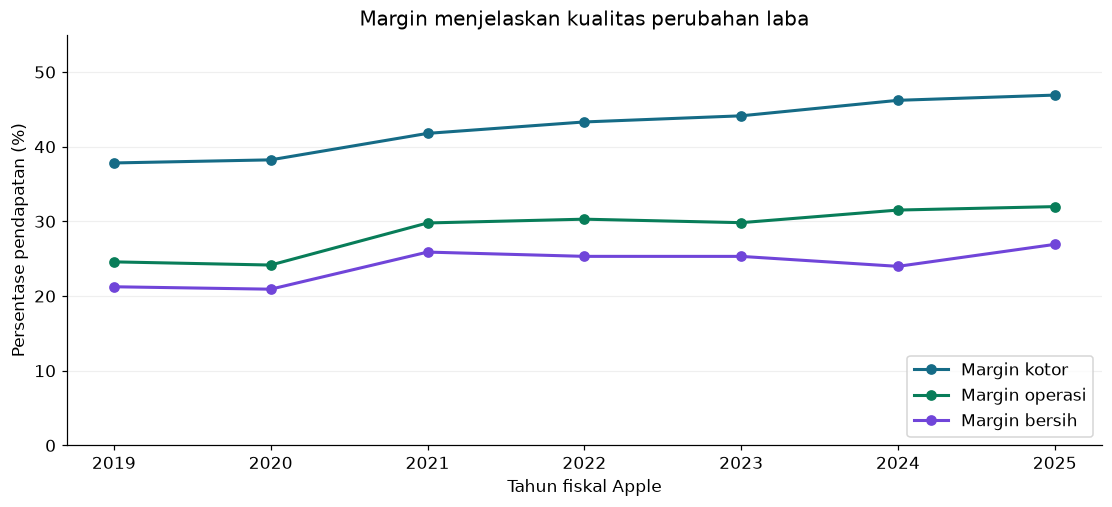

**Informasi:** margin operasi FY2025 **31,97%**, berubah **0,46 poin persentase**. Margin bersih **26,92%**, berubah **2,94 poin persentase**.

In [7]:
fig, ax = plt.subplots(figsize=(10,4.5),layout='constrained')
for kol,label,warna in [('margin_kotor_pct','Margin kotor',WARNA['utama']),
                        ('margin_operasi_pct','Margin operasi',WARNA['hijau']),
                        ('margin_bersih_pct','Margin bersih',WARNA['ungu'])]:
    ax.plot(annual['tahun_fiskal'],annual[kol],marker='o',label=label,color=warna,linewidth=2)
ax.set(ylim=(0,55),xlabel='Tahun fiskal Apple',ylabel='Persentase pendapatan (%)',title='Margin menjelaskan kualitas perubahan laba')
ax.set_xticks(annual['tahun_fiskal']); ax.legend(loc='lower right'); ax.grid(axis='y',alpha=.2)
simpan_grafik(fig,'02_margin.png')
delta_operasi = float(terkini['margin_operasi_pct']-sebelumnya['margin_operasi_pct'])
delta_bersih = float(terkini['margin_bersih_pct']-sebelumnya['margin_bersih_pct'])
display(Markdown(f'**Informasi:** margin operasi FY2025 **{angka(terkini["margin_operasi_pct"])}%**, '
                 f'berubah **{angka(delta_operasi)} poin persentase**. Margin bersih '
                 f'**{angka(terkini["margin_bersih_pct"])}%**, berubah **{angka(delta_bersih)} poin persentase**.'))

**Konteks sumber eksternal:** 10-K FY2025, Note 7, menyebut beban pajak satu kali bersih sekitar
**10,2 miliar USD pada FY2024** terkait keputusan State Aid. Ini konteks penting untuk membaca
kenaikan margin bersih FY2025, bukan hasil yang diturunkan sendiri dari CSV.
[Sumber resmi SEC](https://www.sec.gov/Archives/edgar/data/320193/000032019325000079/aapl-20250927.htm).

**Informasi strategis:** evaluasi target laba sebaiknya memisahkan kinerja operasi dan dampak pos pajak.
CSV belum cukup untuk mengatribusikan seluruh perubahan laba kepada satu sebab. Grafik mempertahankan
angka GAAP asli, tanpa mengganti laba dengan angka yang “dinormalisasi” secara sembarang.

## 7. Visual 3 Pertumbuhan laba dan kas

Batang berkelompok membandingkan perubahan tahun yang sama. Baseline nol dan warna tetap
memperlihatkan tanda negatif tanpa sumbu ganda. Tahun 2019 tidak ditampilkan karena dataset analisis
dimulai pada tahun itu, sehingga tidak ada pembanding 2018 dalam tabel terpilih.

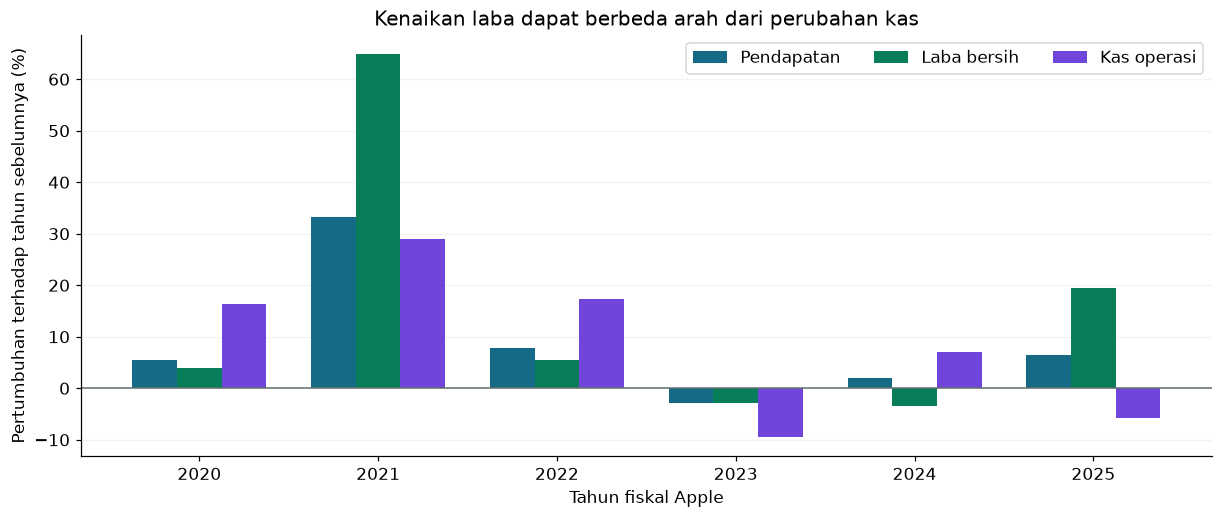

**Informasi:** FY2025 laba bersih naik **19,50%**, sementara kas operasi berubah **-5,73%**. Ini adalah perbedaan arah dua metrik akuntansi, bukan bukti manipulasi atau krisis likuiditas.

In [8]:
growth = annual.dropna(subset=['pendapatan_yoy_pct']).copy()
fig,ax = plt.subplots(figsize=(11,4.6),layout='constrained')
x=np.arange(len(growth)); width=.25
for offset,kol,label,warna in [(-width,'pendapatan_yoy_pct','Pendapatan',WARNA['utama']),
                              (0,'laba_bersih_yoy_pct','Laba bersih',WARNA['hijau']),
                              (width,'arus_kas_operasi_yoy_pct','Kas operasi',WARNA['ungu'])]:
    ax.bar(x+offset,growth[kol],width,label=label,color=warna)
ax.axhline(0,color=WARNA['abu'],linewidth=1)
ax.set_xticks(x,growth['tahun_fiskal'])
ax.set(xlabel='Tahun fiskal Apple',ylabel='Pertumbuhan terhadap tahun sebelumnya (%)',title='Kenaikan laba dapat berbeda arah dari perubahan kas')
ax.legend(ncol=3); ax.grid(axis='y',alpha=.15); ax.set_axisbelow(True)
simpan_grafik(fig,'03_pertumbuhan_yoy.png')
display(Markdown(f'**Informasi:** FY2025 laba bersih naik **{angka(terkini["laba_bersih_yoy_pct"])}%**, '
                 f'sementara kas operasi berubah **{angka(terkini["arus_kas_operasi_yoy_pct"])}%**. '
                 'Ini adalah perbedaan arah dua metrik akuntansi, bukan bukti manipulasi atau krisis likuiditas.'))

**Informasi strategis:** skenario anggaran yang hanya mengikuti pertumbuhan laba dapat mengabaikan
perubahan kas. **Usulan:** periksa rekonsiliasi laba ke arus kas dan kebutuhan modal kerja sebelum
menetapkan ruang investasi. Satu indikator saja tidak cukup untuk menilai kesehatan keseluruhan perusahaan.

## 8. Visual 4 Kas operasi capex dan FCF sederhana

Batang berkelompok memakai satu skala miliar USD. CFO, capex, dan FCF ditampilkan terpisah,
**tidak ditumpuk** karena FCF merupakan hasil CFO dikurangi capex, bukan komponen tambahan.

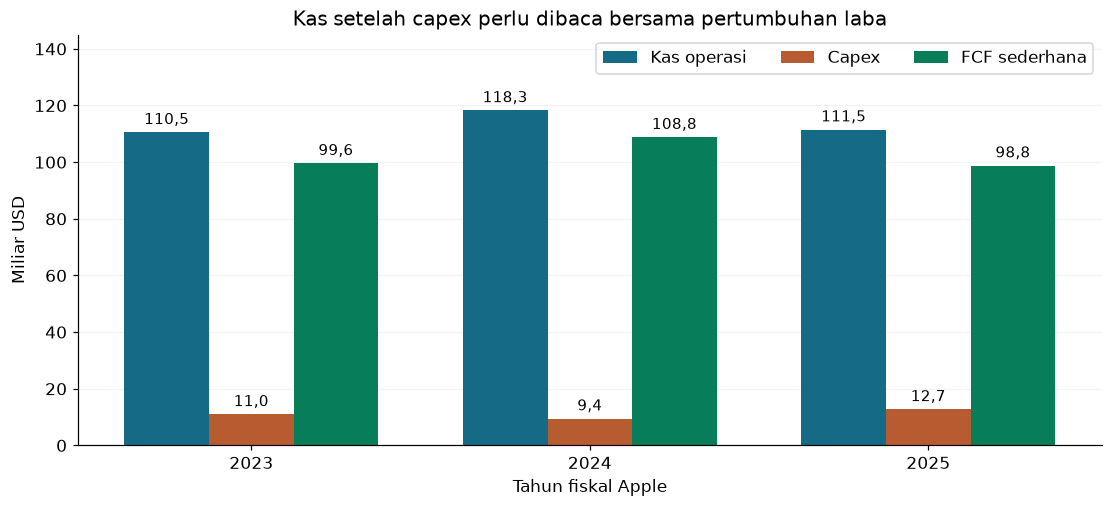

**Informasi:** FCF sederhana FY2025 = **111,48 − 12,71 = 98,77 miliar USD**. Perubahannya **-9,23%** dari FY2024.

In [9]:
cash = annual[annual['tahun_fiskal'].ge(2023)]
x=np.arange(len(cash)); width=.25
fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
for offset,kol,label,warna in [(-width,'arus_kas_operasi','Kas operasi',WARNA['utama']),
                              (0,'capex','Capex',WARNA['jingga']),
                              (width,'fcf_sederhana','FCF sederhana',WARNA['hijau'])]:
    bars=ax.bar(x+offset,cash[kol]/1e9,width,label=label,color=warna)
    ax.bar_label(bars,labels=[angka(v/1e9,1) for v in cash[kol]],padding=3,fontsize=10)
ax.set_xticks(x,cash['tahun_fiskal'])
ax.set(ylim=(0,145),xlabel='Tahun fiskal Apple',ylabel='Miliar USD',title='Kas setelah capex perlu dibaca bersama pertumbuhan laba')
ax.legend(ncol=3); ax.grid(axis='y',alpha=.15); ax.set_axisbelow(True)
simpan_grafik(fig,'04_kas_capex_fcf.png')
display(Markdown(f'**Informasi:** FCF sederhana FY2025 = **{angka(terkini["arus_kas_operasi"]/1e9)} − '
                 f'{angka(terkini["capex"]/1e9)} = {angka(terkini["fcf_sederhana"]/1e9)} miliar USD**. '
                 f'Perubahannya **{angka(terkini["fcf_yoy_pct"])}%** dari FY2024.'))

**Informasi strategis:** untuk skenario penetapan anggaran, perbedaan arah laba dan FCF menjadi
alasan mengecek pembentukan kas dan komitmen belanja. **Usulan:** siapkan skenario kebutuhan kas
sebelum mengubah anggaran. FCF sederhana bukan saldo kas, bukan laba, dan belum memperhitungkan
semua kebutuhan pembiayaan, dividen, atau akuisisi.

## 9. Visual 5 Jembatan pendapatan menuju laba FY2025

Waterfall memperlihatkan aritmetika antartingkat laba. “Beban operasi” di sini diturunkan dari
laba kotor dikurangi laba operasi. “Selisih menuju laba bersih” menggabungkan dampak bersih pos
nonoperasi dan pajak, sehingga tidak diberi label seolah-olah seluruhnya pajak.

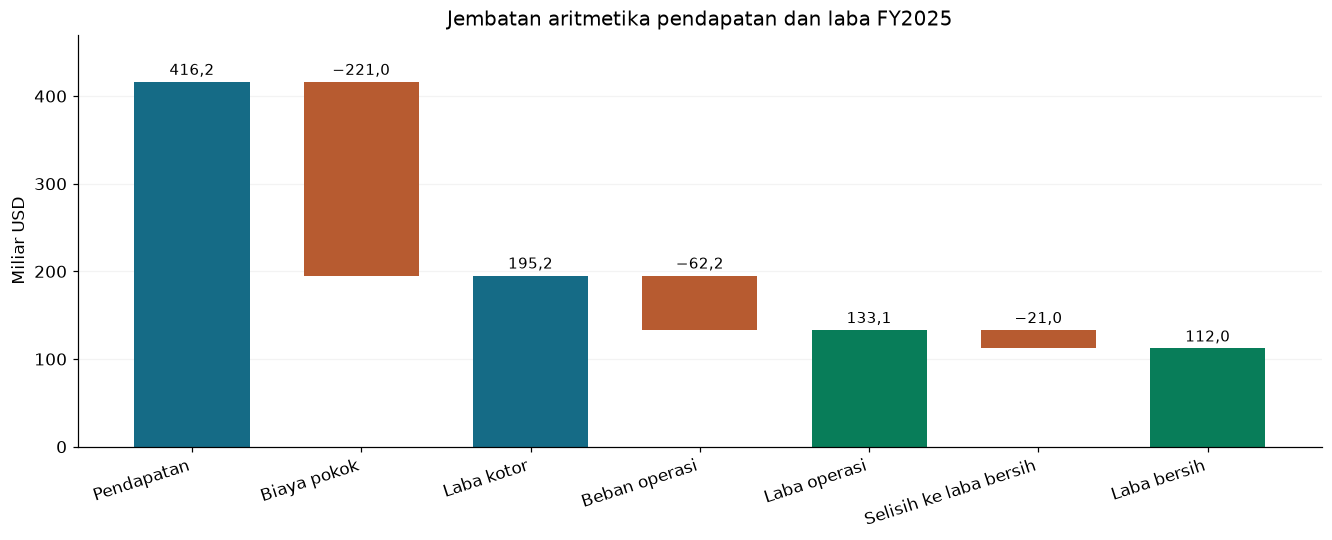

In [10]:
r=terkini
rev,gross,op,net=[float(r[k]/1e9) for k in ['pendapatan','laba_kotor','laba_operasi','laba_bersih']]
cost=rev-gross; opex=gross-op; residual=op-net
labels=['Pendapatan','Biaya pokok','Laba kotor','Beban operasi','Laba operasi','Selisih ke laba bersih','Laba bersih']
heights=[rev,cost,gross,opex,op,residual,net]
bottom=[0,gross,0,op,0,net,0]
colors=[WARNA['utama'],WARNA['jingga'],WARNA['utama'],WARNA['jingga'],WARNA['hijau'],WARNA['jingga'],WARNA['hijau']]
fig,ax=plt.subplots(figsize=(12,4.8),layout='constrained')
ax.bar(range(7),heights,bottom=bottom,color=colors,width=.68)
for i,(h,base) in enumerate(zip(heights,bottom)):
    sign='−' if i in [1,3,5] else ''
    ax.text(i,base+h+8,sign+angka(h,1),ha='center',fontsize=10)
ax.set_xticks(range(7),labels,rotation=18,ha='right')
ax.set(ylim=(0,470),ylabel='Miliar USD',title='Jembatan aritmetika pendapatan dan laba FY2025')
ax.grid(axis='y',alpha=.15); ax.set_axisbelow(True)
simpan_grafik(fig,'05_jembatan_laba.png')
assert np.isclose(rev-cost-opex-residual,net)

**Informasi:** diagram menjelaskan hubungan aritmetika metrik, bukan menjelaskan penyebab perubahan
antarperiode. **Informasi strategis:** pada evaluasi kinerja, tentukan terlebih dahulu tingkat laba
yang sesuai dengan tujuan, lalu telusuri komponennya dalam laporan resmi.

## 10. Ringkasan informasi dan informasi strategis

| Informasi dari visual | Informasi strategis untuk skenario perencanaan | Usulan yang perlu diuji |
|---|---|---|
| Pendapatan dan laba FY2025 meningkat | Evaluasi keberlanjutan dengan membedakan operasi dan pos pajak | Tinjau target laba bersama margin operasi |
| Kas operasi FY2025 turun saat laba naik | Pertumbuhan laba tidak cukup untuk menentukan kelonggaran anggaran kas | Periksa rekonsiliasi arus kas dan modal kerja |
| FCF sederhana FY2025 lebih rendah | Perencanaan belanja perlu memperhitungkan pembentukan kas dan komitmen | Uji beberapa skenario anggaran sebelum keputusan |

## 11. Batasan dan prinsip visualisasi

- Seluruh grafik menyebut periode fiskal, satuan, dan definisi perhitungan. Tidak ada grafik harga saham.
- Sumbu tunggal dan panel terpisah mencegah kesan hubungan yang dibuat oleh dua skala vertikal berbeda.
- Data asli mengandung periode berulang. Pemilihan fakta harus mempertahankan `accn` agar dapat ditelusuri.
- Snapshot terakhir 19 Oktober 2026 menurut metadata. Ini bukan hasil terbaru dari API saat notebook dijalankan.
- Analisis tahunan memakai 2019–2025. Fakta 2026 yang masih parsial tidak dibandingkan sebagai tahun penuh.
- FY2023 memiliki 53 minggu, sementara FY2024 dan FY2025 52 minggu menurut 10-K. Grafik memakai nominal
  tahun fiskal, tanpa normalisasi mingguan. Perbedaan lama periode dapat memengaruhi perbandingan.
- Tidak ada inferensi harga, valuasi, risiko pasar, atau rekomendasi investasi dari data ini.
- Penjelasan pajak berasal dari laporan resmi. CSV sendiri belum mengisolasi seluruh sebab perubahan.

## 12. Penjelasan saat responsi

“Aku mengecek bahwa Apple Stocks yang tersedia sebenarnya berisi laporan keuangan SEC. Aku memilih
tahun fiskal penuh dan satu filing yang sama untuk setiap kumpulan metrik agar angka pembanding tidak
terhitung berulang. Grafik menunjukkan perubahan pendapatan, margin, dan kas. Angka-angka itu adalah
informasi. Makna strategisnya adalah anggaran dan target laba perlu dinilai bersama pembentukan kas,
terutama ketika laba dan kas bergerak berbeda arah. Aku tidak menyimpulkan arah harga saham.”

In [11]:
annual.to_csv(HASIL/'apple_tahunan_2019_2025.csv',index=False)
jejak.to_csv(HASIL/'jejak_fakta_terpilih.csv',index=False)
coverage.to_csv(HASIL/'audit_kelengkapan_periode_filing.csv',index=False)
ringkasan={
 'financial_facts':len(raw),'filings':len(filings),'tahun':annual['tahun_fiskal'].tolist(),
 'fakta_terpilih':len(jejak),'calon_tahunan':len(calon),
 'pendapatan_2025_miliar':float(terkini['pendapatan']/1e9),
 'laba_2025_miliar':float(terkini['laba_bersih']/1e9),
 'pendapatan_yoy_pct':float(terkini['pendapatan_yoy_pct']),
 'laba_yoy_pct':float(terkini['laba_bersih_yoy_pct']),
 'cfo_yoy_pct':float(terkini['arus_kas_operasi_yoy_pct']),
 'fcf_2025_miliar':float(terkini['fcf_sederhana']/1e9),
 'fcf_yoy_pct':float(terkini['fcf_yoy_pct']),
 'margin_operasi_2025_pct':float(terkini['margin_operasi_pct']),
 'margin_bersih_2025_pct':float(terkini['margin_bersih_pct']),
 'snapshot':metadata['refreshed_at_utc'],
 'sha256':hashlib.sha256((SUMBER/'financial_facts.csv').read_bytes()).hexdigest(),
}
(HASIL/'ringkasan.json').write_text(json.dumps(ringkasan,indent=2),encoding='utf-8')
assert np.allclose(annual['fcf_sederhana'],annual['arus_kas_operasi']-annual['capex'])
assert not jejak.duplicated(['start','end','concept']).any()
print('Selesai. Tabel dan jejak pemilihan fakta tersimpan di',HASIL)

Selesai. Tabel dan jejak pemilihan fakta tersimpan di /home/luis/Documents/Codelabs/Sub-Riset/RISET30OKTOBER/Analisis/hasil/apple


## Sumber

- [Dataset Kaggle Apple](https://www.kaggle.com/datasets/blixture/apple-stocks), snapshot lokal yang disediakan pengguna.
- `Apple/Dataset/refresh_metadata.json`, `company_profile.json`, `data_dictionary.csv`, serta README dalam ZIP.
- [SEC EDGAR API documentation](https://www.sec.gov/search-filings/edgar-application-programming-interfaces):
  pengertian Company Facts, satuan, dan perhatian terhadap kalender pelaporan.
- [Apple FY2025 Form 10-K](https://www.sec.gov/Archives/edgar/data/320193/000032019325000079/aapl-20250927.htm),
  laporan operasi, arus kas, kebijakan tahun fiskal, dan Note 7 untuk konteks pajak FY2024.
- Nilai utama dan perhitungan di notebook berasal dari CSV lokal. Penelusuran konteks: 30 Oktober 2026.